# 05 - Preprocessing for the models

**Goal:** turn the clean data into train / test sets ready for the models.

- **Input:** `CSE_CIC_IDS2018_clean.parquet` (notebook 03)
- **Output** (folder `data/model_ready/`): `X_train`, `X_test`, `y_train`, `y_test`, the scaler, the label encoder and the feature list

| Step | What | Why |
|---|---|---|
| 1 | Encode the labels as numbers | Models need numeric targets |
| 2 | Shift the `-1` placeholder | All features must be ≥ 0 for the log transform |
| 3 | Stratified train / test split (80 / 20) | Same class proportions in both sets |
| 4 | Remove highly correlated features (train only) | Redundant features add noise |
| 5 | Fit the scaler on the train set only | `log1p` + standardization, no test leakage |

In [1]:
# Imports
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from google.colab import drive

# Mount Drive
drive.mount("/content/drive")

# Paths
BASE = Path("/content/drive/MyDrive/Projects/CSE-CIC-IDS2018")
DATA_DIR = BASE / "data" / "processed"
READY_DIR = BASE / "data" / "model_ready"
READY_DIR.mkdir(exist_ok=True)
SEED = 42
pd.set_option("display.max_columns", 100)

Mounted at /content/drive


## 0. Load the clean data

In [2]:
df = pd.read_parquet(DATA_DIR / "CSE_CIC_IDS2018_clean.parquet")
feature_cols = [c for c in df.columns if c != "Label"]

print("Shape:", df.shape)
df["Label"].value_counts()

Shape: (2966102, 71)


,count
Label,
Benign,1643296
DDoS attacks-LOIC-HTTP,575012
DDOS attack-HOIC,198861
DoS attacks-Hulk,145199
Bot,144535
Infilteration,111473
SSH-Bruteforce,94041
DoS attacks-GoldenEye,41392
DoS attacks-Slowloris,9712


## 1. Encode the labels
Each class name gets a number (0, 1, 2...). The encoder is saved to convert the predictions back into names.

In [3]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y = encoder.fit_transform(df["Label"]).astype(np.int16)
X = df[feature_cols].astype("float32")
del df

pd.DataFrame({"class": encoder.classes_}).rename_axis("code")

,class
code,
0,Benign
1,Bot
2,DDOS attack-HOIC
3,DDOS attack-LOIC-UDP
4,DDoS attacks-LOIC-HTTP
5,DoS attacks-GoldenEye
6,DoS attacks-Hulk
7,DoS attacks-Slowloris
8,Infilteration


## 2. Shift the `-1` placeholder
In `Init Fwd Win Byts` and `Init Bwd Win Byts`, `-1` means "not available". Adding 1 to these two columns makes
every value ≥ 0 (needed for `log1p` in step 5) while keeping "not available" (now 0) different from a real window of 0 (now 1).

In [4]:
WIN_COLS = ["Init Fwd Win Byts", "Init Bwd Win Byts"]
X[WIN_COLS] = X[WIN_COLS] + 1

print("Minimum value over all features:", X.min().min())

Minimum value over all features: 0.0


## 3. Train / test split
80% for training, 20% for testing. `stratify=y` keeps the same class proportions in both sets.
The test set keeps the **real** distribution and is never resampled.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
del X

print("Train:", X_train.shape)
print("Test :", X_test.shape)

names = encoder.classes_
pd.DataFrame({
    "train": pd.Series(names[y_train]).value_counts(),
    "test": pd.Series(names[y_test]).value_counts(),
})

Train: (2372881, 70)
Test : (593221, 70)


,train,test
Benign,1314636,328660
DDoS attacks-LOIC-HTTP,460009,115003
DDOS attack-HOIC,159089,39772
DoS attacks-Hulk,116159,29040
Bot,115628,28907
Infilteration,89178,22295
SSH-Bruteforce,75233,18808
DoS attacks-GoldenEye,33114,8278
DoS attacks-Slowloris,7770,1942
DDOS attack-LOIC-UDP,1384,346


## 4. Remove highly correlated features
If two features have a correlation above 0.99, they carry the same information: we keep one.
The correlation is computed on the **train set only** (on a sample of 200,000 rows, for speed).

In [6]:
CORR_THRESHOLD = 0.99

sample = X_train.sample(min(200_000, len(X_train)), random_state=SEED)
corr = sample.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

to_drop = [c for c in upper.columns if (upper[c] > CORR_THRESHOLD).any()]
print(f"Features removed ({len(to_drop)}):", to_drop)

X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)
features = list(X_train.columns)
print(f"Features kept: {len(features)}")

Features removed (21): ['TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Max', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'SYN Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt', 'Pkt Size Avg', 'Fwd Seg Size Avg', 'Bwd Seg Size Avg', 'Subflow Fwd Pkts', 'Subflow Fwd Byts', 'Subflow Bwd Pkts', 'Subflow Bwd Byts', 'Fwd Act Data Pkts', 'Idle Max', 'Idle Min']
Features kept: 49


## 5. Scaler (fitted on the train set only)
1. `log1p` reduces the huge skew of the features (e.g. bytes/s from 0 to 10⁹)
2. `StandardScaler` gives each feature mean 0 and standard deviation 1

The scaler is **saved, not applied** to the saved data: tree models (Random Forest, XGBoost...) use the raw values,
while Logistic Regression and neural networks apply the scaler when they load the data.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

scaler = make_pipeline(FunctionTransformer(np.log1p), StandardScaler())
scaler.fit(X_train)

check = pd.DataFrame(scaler.transform(X_train.head(100_000)), columns=features)
check.describe().T[["mean", "std", "min", "max"]].head(10).round(2)

,mean,std,min,max
Dst Port,0.0,1.0,-2.37,2.02
Protocol,-0.0,1.0,-5.20,2.14
Flow Duration,0.0,1.0,-2.65,1.49
Tot Fwd Pkts,-0.0,1.0,-1.14,14.63
Tot Bwd Pkts,-0.0,1.0,-1.25,8.88
Fwd Pkt Len Max,-0.0,1.0,-1.38,1.56
Fwd Pkt Len Min,-0.0,1.0,-0.39,5.36
Fwd Pkt Len Mean,-0.0,1.0,-1.40,2.27
Fwd Pkt Len Std,-0.0,1.0,-1.08,1.84
Bwd Pkt Len Max,-0.0,1.0,-1.33,1.40


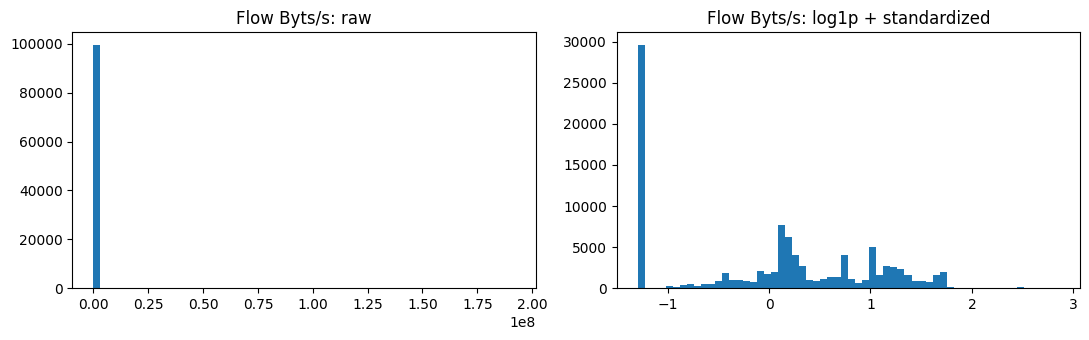

In [8]:
col = "Flow Byts/s" if "Flow Byts/s" in features else features[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(X_train[col].head(100_000), bins=60)
axes[0].set_title(f"{col}: raw")
axes[1].hist(check[col], bins=60)
axes[1].set_title(f"{col}: log1p + standardized")
plt.tight_layout()
plt.show()

## 6. Save

In [9]:
X_train.to_parquet(READY_DIR / "X_train.parquet", index=False)
X_test.to_parquet(READY_DIR / "X_test.parquet", index=False)
np.save(READY_DIR / "y_train.npy", y_train)
np.save(READY_DIR / "y_test.npy", y_test)
joblib.dump(scaler, READY_DIR / "scaler.joblib")
joblib.dump(encoder, READY_DIR / "label_encoder.joblib")
json.dump(features, open(READY_DIR / "features.json", "w"), indent=1)

for f in sorted(READY_DIR.iterdir()):
    print(f"{f.name:22s} {f.stat().st_size / 1024**2:8.1f} MB")

X_test.parquet             48.2 MB
X_train.parquet           186.5 MB
features.json               0.0 MB
label_encoder.joblib        0.0 MB
scaler.joblib               0.0 MB
y_test.npy                  1.1 MB
y_train.npy                 4.5 MB


## Summary (fill in after running)
- Classes: 11 | Features kept: 49 (removed 21 correlated features)
- Train: 2,372,881 rows | Test: 593,221 rows